In [1]:
# Import Library
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ttest_ind, mannwhitneyu, chi2_contingency
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, 
    precision_score, 
    recall_score, 
    f1_score, 
    roc_auc_score, 
    confusion_matrix
)
from sklearn.inspection import permutation_importance
from pycaret.classification import *

import warnings
warnings.filterwarnings('ignore')

# Data Understanding

In [2]:
# Load Dataset
df = pd.read_csv('../data/employee_attrition_dataset.csv')

# Preview Dataset
df.sample(5).T

,8834,1079,4501,3229,9482
Employee_ID,208835,201080,204502,203230,209483
Age,50,49,43,35,24
Gender,Female,Male,Male,Female,Male
Marital_Status,Married,Single,Married,Married,Single
Education_Level,Master,Bachelor,Master,Bachelor,PhD
Department,Operations,Operations,HR,IT,IT
Job_Role,Logistics Coordinator,Operations Executive,HR Manager,System Administrator,IT Manager
Employment_Type,Full-Time,Full-Time,Full-Time,Full-Time,Full-Time
Years_At_Company,3,11,5,3,0
Years_In_Current_Role,2,1,4,0,0


In [3]:
# Identifikasi Unique Value Pada Kolom Kategorikal Pada Dataset
categorical_columns = ['Gender', 'Marital_Status', 'Education_Level', 'Department', 'Job_Role',
                       'Employment_Type', 'Job_Level', 'Performance_Rating', 'Job_Satisfaction', 'Work_Life_Balance',
                       'Environment_Satisfaction', 'Relationship_Satisfaction', 'Overtime', 'Remote_Work', 'Business_Travel',
                       'Manager_Rating', 'Promotion_Last_5_Years', 'Stock_Option', 'Attrition']

for col in categorical_columns:
  print(f"{col}: {df[col].nunique()} unique values")
  print(df[col].value_counts())
  print("\n")

Gender: 2 unique values
Gender
Male      8420
Female    6580
Name: count, dtype: int64


Marital_Status: 3 unique values
Marital_Status
Married     7582
Single      5579
Divorced    1839
Name: count, dtype: int64


Education_Level: 4 unique values
Education_Level
Bachelor       7468
Master         3728
High School    3038
PhD             766
Name: count, dtype: int64


Department: 6 unique values
Department
IT            4074
Sales         3246
Operations    2404
Finance       2252
Marketing     1808
HR            1216
Name: count, dtype: int64


Job_Role: 24 unique values
Job_Role
Software Engineer        1048
Data Analyst             1020
IT Manager               1011
System Administrator      995
Sales Manager             876
Account Executive         819
Sales Executive           785
Business Development      766
Operations Executive      634
Quality Analyst           602
Logistics Coordinator     598
Accountant                582
Operations Manager        570
Auditor              

In [4]:
# Identifikasi Unique Value Pada Kolom Numerik Pada Dataset
numerical_columns = ['Age', 'Years_At_Company', 'Years_In_Current_Role', 'Monthly_Income', 'Salary_Hike_Percent',
                     'Training_Hours_Last_Year', 'Distance_From_Home', 'Commute_Time_Minutes', 'Number_Of_Projects', 'Team_Size',
                     'Absence_Days', 'Attrition_Risk_Score']

for col in numerical_columns:
  unique_count = df[col].nunique()
  print(f"{col}: {df[col].nunique()} unique values")
  print(f"Values: {df[col].unique()[:10]}")
  print("\n")

Age: 43 unique values
Values: [26 45 39 22 31 51 18 32 47 28]


Years_At_Company: 34 unique values
Values: [ 1  4  3 12  0 20  9 14  5  8]


Years_In_Current_Role: 30 unique values
Values: [ 0  1  3  4 18  6  2  9  5 10]


Monthly_Income: 8085 unique values
Values: [ 7673  9060 10899  8205  9981  4401  5155  5231 18271 14525]


Salary_Hike_Percent: 221 unique values
Values: [11.  16.5 15.6 11.7 18.6 12.6 13.2 15.1 13.  13.1]


Training_Hours_Last_Year: 98 unique values
Values: [58 26 34 73 48 42 13 43 59  5]


Distance_From_Home: 60 unique values
Values: [ 6 15  5 11 14  8 24 12  7 37]


Commute_Time_Minutes: 146 unique values
Values: [23 64 15 32 42 47 34 43 21 92]


Number_Of_Projects: 12 unique values
Values: [ 7  6  3  5  1  4  2 10  8  9]


Team_Size: 22 unique values
Values: [ 7 11  3 12  4 13  9  6  2  8]


Absence_Days: 20 unique values
Values: [ 7 10  9 11  5  6  8  4  3  1]


Attrition_Risk_Score: 101 unique values
Values: [97 72 45 49 20 77 74 70 41 33]




In [5]:
# Identifikasi Duplicate Row Pada Dataset
print(f"Jumlah duplicate row: {df.duplicated().sum()}")

Jumlah duplicate row: 0


In [6]:
# Identifikasi Missing Value Pada Dataset
print("Jumlah missing value:")
missing_count = df.isnull().sum()
print(missing_count[missing_count > 0])

print("\nPersentase missing value:")
missing_pct = (df.isnull().sum() / len(df) * 100).round(2)
missing_summary = pd.DataFrame({
  'Jumlah': missing_count,
  'Persentase (%)': missing_pct
})
print(missing_summary[missing_summary['Jumlah'] > 0].sort_values('Persentase (%)', ascending=False))

Jumlah missing value:
Series([], dtype: int64)

Persentase missing value:
Empty DataFrame
Columns: [Jumlah, Persentase (%)]
Index: []


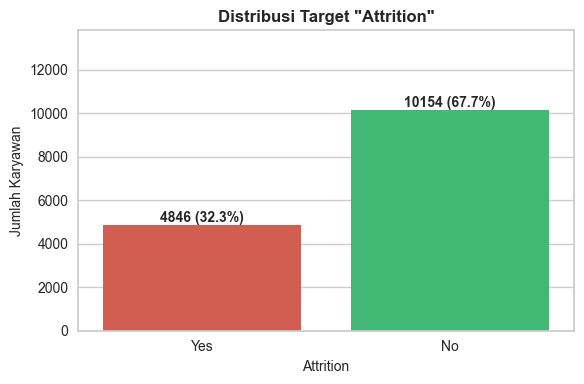

In [7]:
# Identifikasi Distribusi Ratio Target
plt.figure(figsize=(6, 4))

ax = sns.countplot(
    x=df['Attrition'],
    hue=df['Attrition'],
    order=['Yes', 'No'],
    palette={'Yes': '#e74c3c', 'No': '#2ecc71'},
    legend=False
)

plt.title('Distribusi Target "Attrition"', fontsize=12, fontweight='bold')
plt.xlabel('Attrition', fontsize=10)
plt.ylabel('Jumlah Karyawan', fontsize=10)

total = len(df['Attrition'])
for p in ax.patches:
    height = p.get_height()
    if height > 0:
        percentage = (height / total) * 100
        ax.annotate(f'{int(height)} ({percentage:.1f}%)',
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='center',
                    xytext=(0, 5),
                    textcoords='offset points',
                    fontsize=10, fontweight='bold')

plt.ylim(0, max(ax.get_yticks()) * 1.15)
plt.tight_layout()
plt.show()

# Exploratory Data Analysis

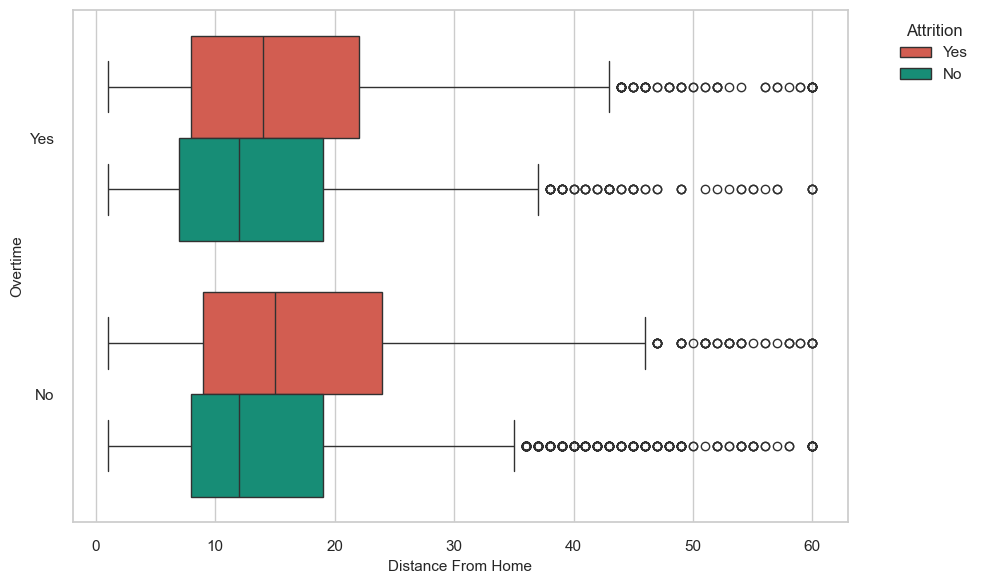

In [8]:
# Membuat Visualisasi Analisis Interaksi Faktor Fisik dan Beban Kerja
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

ax = sns.boxplot(
    data=df,
    x="Distance_From_Home",
    y="Overtime",
    hue="Attrition",
    palette={"Yes": "#e74c3c", "No": "#04a082"},
    orient="h",
)

plt.xlabel("Distance From Home", fontsize=11)
plt.ylabel("Overtime", fontsize=11)
plt.legend(title="Attrition", bbox_to_anchor=(1.05, 1), loc="upper left")

plt.tight_layout()
plt.show()

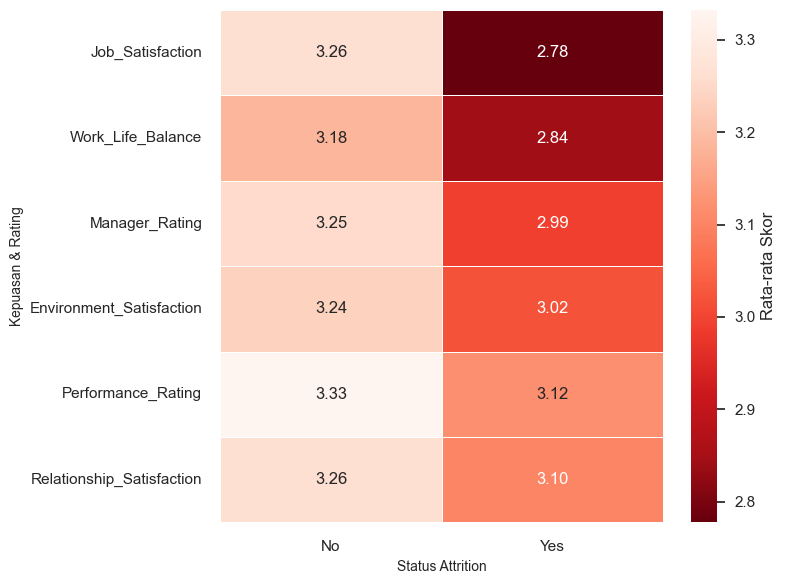

In [9]:
# Membuat Visualisasi untuk Analisis Tingkat Kepuasan dan Rating Karyawan Pada Data Training
satisfaction_cols = [
    'Job_Satisfaction',
    'Work_Life_Balance',
    'Environment_Satisfaction',
    'Relationship_Satisfaction',
    'Manager_Rating',
    'Performance_Rating'
]

avg_satisfaction = df.groupby('Attrition')[satisfaction_cols].mean().T

avg_satisfaction['Selisih'] = abs(avg_satisfaction['Yes'] - avg_satisfaction['No'])
avg_satisfaction = avg_satisfaction.sort_values(by='Selisih', ascending=False)
avg_satisfaction = avg_satisfaction.drop(columns=['Selisih'])

plt.figure(figsize=(8, 6))
sns.heatmap(
    avg_satisfaction,
    annot=True,
    cmap='Reds_r',
    fmt='.2f',
    linewidths=0.5,
    cbar_kws={'label': 'Rata-rata Skor'}
)
plt.xlabel('Status Attrition', fontsize=10)
plt.ylabel('Kepuasan & Rating', fontsize=10)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Baseline Model Evaluation

In [10]:
# Split Dataset
train_df, test_df = train_test_split(
    df, 
    test_size=0.2, 
    random_state=42, 
    stratify=df['Attrition']
)

# Menghitung Rata-rata "attrition_risk_score" Kelompok Karyawan Resign Sebagai Threshold
mean_resigned_score_train = train_df[train_df['Attrition'] == 'Yes']['Attrition_Risk_Score'].mean()
threshold_used = round(mean_resigned_score_train, 2)

print(f"Threshold yang digunakan (Dihitung dari Rata-rata Data Training): {threshold_used}")

Threshold yang digunakan (Dihitung dari Rata-rata Data Training): 63.83



--- Evaluasi Model Baseline ---
Accuracy  : 0.7940
Precision : 0.8010
Recall    : 0.4819
F1-Score  : 0.6018
ROC-AUC   : 0.8708


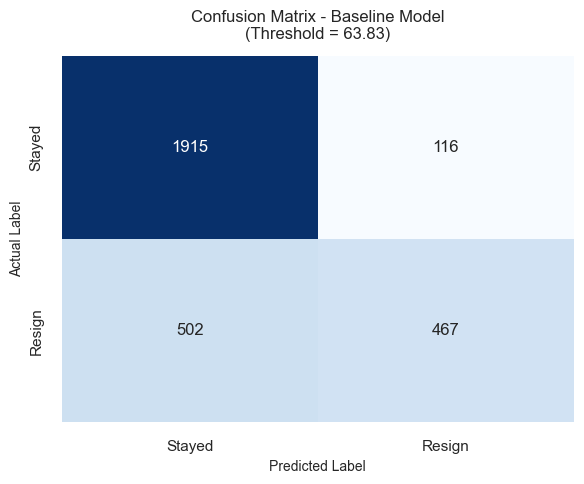

In [11]:
# Evaluasi Model Baseline
y_true_test = (test_df['Attrition'] == 'Yes').astype(int)
y_pred_baseline = (test_df['Attrition_Risk_Score'] >= threshold_used).astype(int)

# Menghitung Metrik Evaluasi Model Baseline
acc = accuracy_score(y_true_test, y_pred_baseline)
prec = precision_score(y_true_test, y_pred_baseline, zero_division=0)
rec = recall_score(y_true_test, y_pred_baseline, zero_division=0)
f1 = f1_score(y_true_test, y_pred_baseline, zero_division=0)
roc_auc = roc_auc_score(y_true_test, test_df['Attrition_Risk_Score'] / 100.0)
cm = confusion_matrix(y_true_test, y_pred_baseline)

print("\n--- Evaluasi Model Baseline ---")
print(f"Accuracy  : {acc:.4f}")
print(f"Precision : {prec:.4f}")
print(f"Recall    : {rec:.4f}")
print(f"F1-Score  : {f1:.4f}")
print(f"ROC-AUC   : {roc_auc:.4f}")

# Membuat Visualisasi Confusion Matrix
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm, 
    annot=True, 
    fmt='d', 
    cmap='Blues', 
    cbar=False,
    xticklabels=['Stayed', 'Resign'],
    yticklabels=['Stayed', 'Resign']
)
plt.title(f'Confusion Matrix - Baseline Model\n(Threshold = {threshold_used})', fontsize=12, pad=12)
plt.ylabel('Actual Label', fontsize=10)
plt.xlabel('Predicted Label', fontsize=10)
plt.tight_layout()
plt.show()

# Data Preprocessing

In [12]:
# Split Data
train_data, test_data = train_test_split(
    df, test_size=0.2, random_state=42, stratify=df["Attrition"]
)

print(f"Jumlah baris data training: {train_data.shape}")
print(f"\nJumlah baris data testing: {test_data.shape}")

Jumlah baris data training: (12000, 32)

Jumlah baris data testing: (3000, 32)


In [13]:
# Menghapus Feature "Employee_ID" dan "Attrition_Risk_Score"
train_data = train_data.drop(columns=['Employee_ID', 'Attrition_Risk_Score'])
test_data = test_data.drop(columns=['Employee_ID', 'Attrition_Risk_Score'])

In [14]:
# Membuat Function untuk Feature Engineering
def create_features(df):
  df = df.copy()

  # Financial Ratios
  df["Income_Per_Year_At_Company"] = (
      df["Monthly_Income"] * 12 / (df["Years_At_Company"] + 1)
  )
  df["Income_Per_Project"] = df["Monthly_Income"] / (
      df["Number_Of_Projects"] 
  )
  df["Income_Per_Age"] = df["Monthly_Income"] / df["Age"]

  # Career Ratios
  df["Experience_Ratio"] = df["Years_In_Current_Role"] / (
      df["Years_At_Company"] + 1
  )

  # Aggregasi Satisfaction
  sat_cols = [
      "Job_Satisfaction",
      "Work_Life_Balance",
      "Environment_Satisfaction",
      "Relationship_Satisfaction",
  ]
  df["Avg_Satisfaction"] = df[sat_cols].mean(axis=1)

  # Workload & Performance
  df["Workload_Index"] = df["Number_Of_Projects"] * df["Team_Size"]
  df["Projects_Per_Team_Member"] = df["Number_Of_Projects"] / (
      df["Team_Size"] 
  )

  # Commute
  df["Commute_Speed_Index"] = df["Distance_From_Home"] / (
      df["Commute_Time_Minutes"]
  )

  return df

# Melakukan Feature Engineering Pada Data Training & Testing
train_data = create_features(train_data)
test_data = create_features(test_data)

# Menampilkan Hasil Feature Engineering Pada Data Training
train_data.sample(5).T

,5609,10439,9675,10004,4300
Age,20,47,38,42,57
Gender,Male,Male,Male,Female,Female
Marital_Status,Married,Married,Married,Single,Married
Education_Level,Bachelor,Bachelor,Bachelor,Bachelor,High School
Department,HR,Operations,Marketing,Marketing,Finance
Job_Role,HR Executive,Operations Executive,Content Strategist,Content Strategist,Finance Manager
Employment_Type,Full-Time,Part-Time,Full-Time,Full-Time,Full-Time
Years_At_Company,0,2,1,11,9
Years_In_Current_Role,0,1,1,8,0
Monthly_Income,6523,5147,6017,13947,10657


In [15]:
train_data.columns

Index(['Age', 'Gender', 'Marital_Status', 'Education_Level', 'Department',
       'Job_Role', 'Employment_Type', 'Years_At_Company',
       'Years_In_Current_Role', 'Monthly_Income', 'Salary_Hike_Percent',
       'Job_Level', 'Performance_Rating', 'Job_Satisfaction',
       'Work_Life_Balance', 'Environment_Satisfaction',
       'Relationship_Satisfaction', 'Training_Hours_Last_Year', 'Overtime',
       'Remote_Work', 'Business_Travel', 'Distance_From_Home',
       'Commute_Time_Minutes', 'Number_Of_Projects', 'Team_Size',
       'Manager_Rating', 'Absence_Days', 'Promotion_Last_5_Years',
       'Stock_Option', 'Attrition', 'Income_Per_Year_At_Company',
       'Income_Per_Project', 'Income_Per_Age', 'Experience_Ratio',
       'Avg_Satisfaction', 'Workload_Index', 'Projects_Per_Team_Member',
       'Commute_Speed_Index'],
      dtype='object')

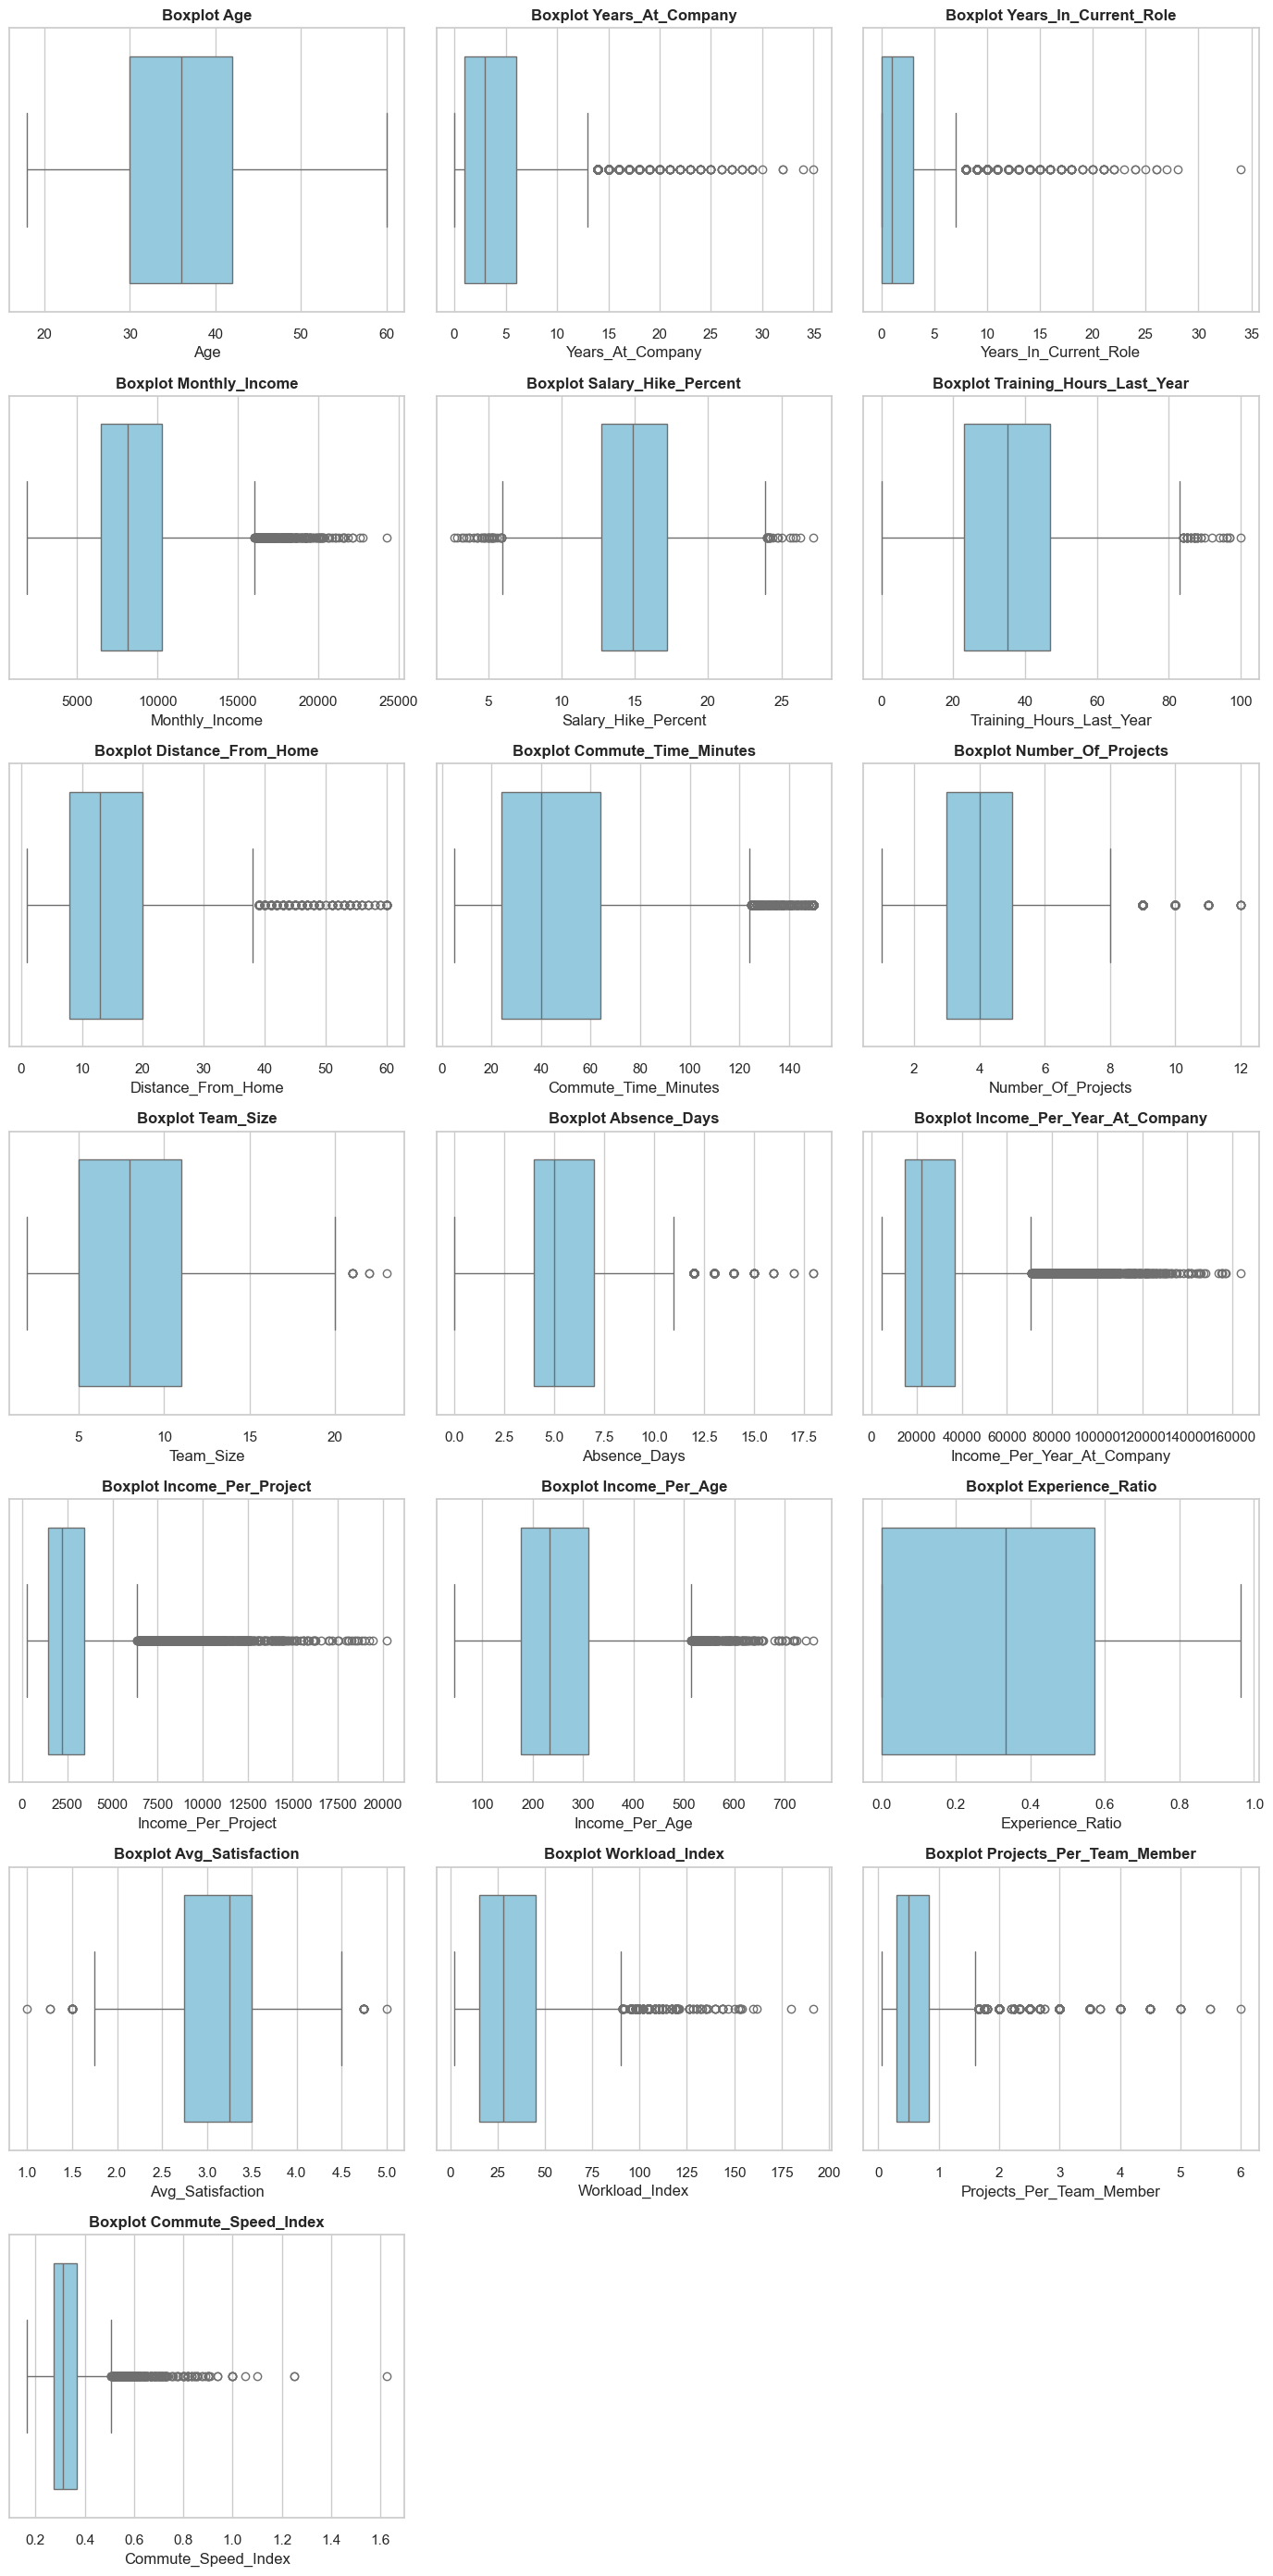

In [16]:
# Identifkasi Outlier Pada Feature Data Training
feature_numerical = ['Age', 'Years_At_Company', 'Years_In_Current_Role', 'Monthly_Income', 'Salary_Hike_Percent',
                     'Training_Hours_Last_Year', 'Distance_From_Home', 'Commute_Time_Minutes', 'Number_Of_Projects', 'Team_Size',
                     'Absence_Days', 'Income_Per_Year_At_Company', 'Income_Per_Project', 'Income_Per_Age', 'Experience_Ratio', 
                     'Avg_Satisfaction', 'Workload_Index', 'Projects_Per_Team_Member', 'Commute_Speed_Index']

n_cols = 3
n_rows = (len(feature_numerical) + n_cols - 1) // n_cols
fig, axes = plt.subplots(n_rows, n_cols, figsize=(14, n_rows * 4))
axes = axes.flatten()


for i, col in enumerate(feature_numerical):
    sns.boxplot(data=train_data, x=col, ax=axes[i], color='skyblue')
    axes[i].set_title(f'Boxplot {col}', fontsize=12, fontweight='bold')
    axes[i].set_xlabel(col)


for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])


plt.tight_layout()
plt.show()

In [17]:
# Menghitung Outlier Masing-masing Feature Data Training
total_outlier_rows = (
    set()
)

print("--- Detail Outlier per Kolom ---")
for col in feature_numerical:
  Q1 = train_data[col].quantile(0.25)
  Q3 = train_data[col].quantile(0.75)
  IQR = Q3 - Q1
  batas_bawah = Q1 - 1.5 * IQR
  batas_atas = Q3 + 1.5 * IQR

  outlier_indices = train_data[
      (train_data[col] < batas_bawah) | (train_data[col] > batas_atas)
  ].index
  total_outlier_rows.update(
      outlier_indices
  )

  outlier = train_data.loc[outlier_indices]
  print(f"Kolom: {col}, Jumlah Outlier: {len(outlier)}")

# Menghitung total keseluruhan dan persentase
jumlah_total_outlier = len(total_outlier_rows)
persentase_outlier = (jumlah_total_outlier / len(train_data)) * 100

print("\n----------------------------------------")
print(f"Total Baris Unik yang Mengandung Outlier: {jumlah_total_outlier}")
print(f"Persentase dari Total Data Training: {persentase_outlier:.2f}%")

--- Detail Outlier per Kolom ---
Kolom: Age, Jumlah Outlier: 0
Kolom: Years_At_Company, Jumlah Outlier: 565
Kolom: Years_In_Current_Role, Jumlah Outlier: 713
Kolom: Monthly_Income, Jumlah Outlier: 274
Kolom: Salary_Hike_Percent, Jumlah Outlier: 54
Kolom: Training_Hours_Last_Year, Jumlah Outlier: 36
Kolom: Distance_From_Home, Jumlah Outlier: 347
Kolom: Commute_Time_Minutes, Jumlah Outlier: 419
Kolom: Number_Of_Projects, Jumlah Outlier: 246
Kolom: Team_Size, Jumlah Outlier: 9
Kolom: Absence_Days, Jumlah Outlier: 252
Kolom: Income_Per_Year_At_Company, Jumlah Outlier: 885
Kolom: Income_Per_Project, Jumlah Outlier: 981
Kolom: Income_Per_Age, Jumlah Outlier: 216
Kolom: Experience_Ratio, Jumlah Outlier: 0
Kolom: Avg_Satisfaction, Jumlah Outlier: 41
Kolom: Workload_Index, Jumlah Outlier: 314
Kolom: Projects_Per_Team_Member, Jumlah Outlier: 914
Kolom: Commute_Speed_Index, Jumlah Outlier: 441

----------------------------------------
Total Baris Unik yang Mengandung Outlier: 4721
Persentase dari

In [18]:
train_data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 12000 entries, 7992 to 14556
Data columns (total 38 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Age                         12000 non-null  int64  
 1   Gender                      12000 non-null  object 
 2   Marital_Status              12000 non-null  object 
 3   Education_Level             12000 non-null  object 
 4   Department                  12000 non-null  object 
 5   Job_Role                    12000 non-null  object 
 6   Employment_Type             12000 non-null  object 
 7   Years_At_Company            12000 non-null  int64  
 8   Years_In_Current_Role       12000 non-null  int64  
 9   Monthly_Income              12000 non-null  int64  
 10  Salary_Hike_Percent         12000 non-null  float64
 11  Job_Level                   12000 non-null  int64  
 12  Performance_Rating          12000 non-null  int64  
 13  Job_Satisfaction            12000

In [19]:
# Melakukan Data Preprocessing, Pelatihan Awal, dan Evaluasi Awal Model dengan PyCaret
clf_setup = setup(
    data=train_data,
    test_data=test_data,
    target='Attrition',
    normalize=True,
    normalize_method='zscore',
    fix_imbalance=True,          
    session_id=42,
    verbose=True
)

print("\n--- Daftar Model untuk Model Employee Attrition Prediction ---")
best_all_models = compare_models(sort='AUC')

,Description,Value
0,Session id,42
1,Target,Attrition
2,Target type,Binary
3,Target mapping,"No: 0, Yes: 1"
4,Original data shape,"(15000, 38)"
5,Transformed data shape,"(19246, 75)"
6,Transformed train set shape,"(16246, 75)"
7,Transformed test set shape,"(3000, 75)"
8,Numeric features,26
9,Categorical features,11



--- Daftar Model untuk Model Employee Attrition Prediction ---


,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC,TT (Sec)
ada,Ada Boost Classifier,0.7757,0.8300,0.7757,0.7707,0.7721,0.4722,0.4739,0.5390
gbc,Gradient Boosting Classifier,0.7743,0.8252,0.7743,0.7668,0.7663,0.4536,0.4602,1.6580
rf,Random Forest Classifier,0.7590,0.8030,0.7590,0.7496,0.7449,0.3998,0.4134,0.7750
lr,Logistic Regression,0.7177,0.7928,0.7177,0.7455,0.7252,0.4009,0.4094,0.9060
ridge,Ridge Classifier,0.7175,0.7926,0.7175,0.7459,0.7250,0.4012,0.4101,0.1750
lda,Linear Discriminant Analysis,0.7175,0.7926,0.7175,0.7459,0.7250,0.4012,0.4101,0.2790
et,Extra Trees Classifier,0.7479,0.7880,0.7479,0.7372,0.7287,0.3598,0.3789,0.6070
svm,SVM - Linear Kernel,0.6951,0.7631,0.6951,0.7267,0.7033,0.3567,0.3658,0.2610
nb,Naive Bayes,0.6107,0.6958,0.6107,0.6830,0.6229,0.2331,0.2533,0.1460
knn,K Neighbors Classifier,0.6310,0.6408,0.6310,0.6493,0.6379,0.1947,0.1964,0.5210


In [20]:
# Menampilkan Langkah-langkah Preprocessing di Dalam Pipeline PyCaret
pipeline_steps = get_config('pipeline').steps
print(pipeline_steps)

[('label_encoding', TransformerWrapperWithInverse(exclude=None, include=None,
                              transformer=LabelEncoder())), ('numerical_imputer', TransformerWrapper(exclude=None,
                   include=['Age', 'Years_At_Company', 'Years_In_Current_Role',
                            'Monthly_Income', 'Salary_Hike_Percent',
                            'Job_Level', 'Performance_Rating',
                            'Job_Satisfaction', 'Work_Life_Balance',
                            'Environment_Satisfaction',
                            'Relationship_Satisfaction',
                            'Training_Hours_Last_Year', 'Distance_From_Home',
                            'Commute_Time_Minutes', 'Number_Of_Projects',
                            'Team_Size', 'Manager_Rating', 'Absence_Days',
                            'Income_Per_Year_At_Company', 'Income_Per_Project',
                            'Income_Per_Age', 'Experience_Ratio',
                            'Avg_Satisfa

# Hyperparameter Tuning & Evaluation Machine Learning Model

## Ada Boost Model

In [21]:
# Mengambil Model Ada Boost dari PyCaret
ada_model = create_model('ada')

# Melakukan Hyperparameter Tuning Model Ada Boost
tuned_ada = tune_model(
    ada_model,       
    optimize='AUC',        
    n_iter=30,             
    choose_better=True
)

,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.7658,0.8201,0.7658,0.7615,0.7631,0.4526,0.4535
1,0.7817,0.8281,0.7817,0.7761,0.7774,0.4829,0.4852
2,0.7800,0.8208,0.7800,0.7756,0.7770,0.4840,0.4852
3,0.7792,0.8336,0.7792,0.7752,0.7766,0.4846,0.4855
4,0.7758,0.8433,0.7758,0.7706,0.7721,0.4724,0.4741
5,0.7658,0.8178,0.7658,0.7601,0.7618,0.4481,0.4499
6,0.8025,0.8544,0.8025,0.7978,0.7984,0.5320,0.5349
7,0.7650,0.8271,0.7650,0.7591,0.7608,0.4458,0.4476
8,0.7767,0.8302,0.7767,0.7711,0.7725,0.4726,0.4747


,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.7683,0.8243,0.7683,0.7625,0.7642,0.4528,0.4547
1,0.7842,0.8276,0.7842,0.7785,0.7796,0.4877,0.4904
2,0.7808,0.8192,0.7808,0.7743,0.7750,0.4754,0.4794
3,0.7792,0.8327,0.7792,0.7746,0.7761,0.4824,0.4837
4,0.7808,0.8438,0.7808,0.7745,0.7752,0.4770,0.4808
5,0.7633,0.8177,0.7633,0.7570,0.7587,0.4403,0.4425
6,0.8058,0.8513,0.8058,0.8010,0.8011,0.5373,0.5413
7,0.7733,0.8301,0.7733,0.7664,0.7674,0.4587,0.4625
8,0.7750,0.8312,0.7750,0.7681,0.7689,0.4619,0.4660


Fitting 10 folds for each of 30 candidates, totalling 300 fits


In [22]:
# Melihat Parameter Terbaik dari Hasil Tuning Model Ada Boost
best_params = tuned_ada.get_params()
for param, value in best_params.items():
    print(f"{param}: {value}")

algorithm: SAMME
estimator: None
learning_rate: 0.4
n_estimators: 260
random_state: 42


,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
0,Ada Boost Classifier,0.7780,0.8337,0.7780,0.7724,0.7738,0.4751,0.4773


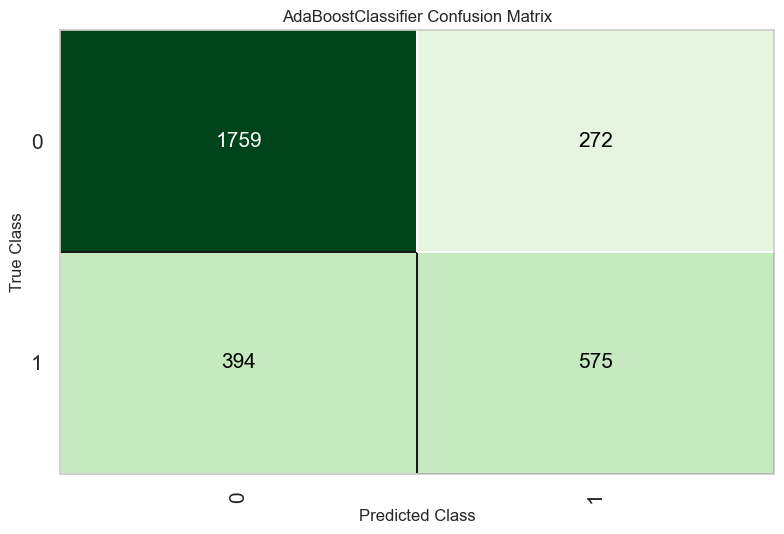

In [23]:
# Melakukan Evaluasi Model Ada Boost yang Telah Dituning
final_predictions = predict_model(tuned_ada)

# Membuat Visualisasi Confusion Matrix untuk Model Ada Boost yang Telah Dituning
plot_model(tuned_ada, plot='confusion_matrix')

## Gradient Boosting Model

In [24]:
# Mengambil Model Gradient Boosting dari PyCaret
gbc_model = create_model('gbc')

# Melakukan Hyperparameter Tuning Model Gradient Boosting
tuned_gbc = tune_model(
    gbc_model,       
    optimize='AUC',        
    n_iter=30,             
    choose_better=True
)

,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.7667,0.8196,0.7667,0.7581,0.7577,0.4322,0.4393
1,0.7717,0.8170,0.7717,0.7637,0.7634,0.4460,0.4526
2,0.7750,0.8163,0.7750,0.7679,0.7687,0.4603,0.4646
3,0.7767,0.8290,0.7767,0.7698,0.7704,0.4651,0.4695
4,0.7883,0.8384,0.7883,0.7820,0.7811,0.4888,0.4952
5,0.7592,0.8081,0.7592,0.7504,0.7511,0.4187,0.4241
6,0.8025,0.8458,0.8025,0.7976,0.7948,0.5199,0.5286
7,0.7717,0.8277,0.7717,0.7637,0.7603,0.4373,0.4485
8,0.7592,0.8235,0.7592,0.7498,0.7496,0.4137,0.4210


,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.7667,0.8223,0.7667,0.7614,0.7631,0.4512,0.4526
1,0.7733,0.8238,0.7733,0.7668,0.7681,0.4601,0.4632
2,0.7808,0.8176,0.7808,0.7745,0.7754,0.4769,0.4804
3,0.7808,0.8307,0.7808,0.7757,0.7770,0.4835,0.4854
4,0.7808,0.8412,0.7808,0.7743,0.7748,0.4755,0.4798
5,0.7658,0.8151,0.7658,0.7599,0.7616,0.4474,0.4493
6,0.7967,0.8474,0.7967,0.7914,0.7918,0.5158,0.5195
7,0.7617,0.8269,0.7617,0.7532,0.7538,0.4252,0.4305
8,0.7750,0.8286,0.7750,0.7675,0.7671,0.4558,0.4621


Fitting 10 folds for each of 30 candidates, totalling 300 fits


In [25]:
# Melihat Parameter Terbaik dari Hasil Tuning Model Gradient Boosting
best_params = tuned_gbc.get_params()
for param, value in best_params.items():
    print(f"{param}: {value}")

ccp_alpha: 0.0
criterion: friedman_mse
init: None
learning_rate: 0.4
loss: log_loss
max_depth: 1
max_features: 1.0
max_leaf_nodes: None
min_impurity_decrease: 0.4
min_samples_leaf: 4
min_samples_split: 2
min_weight_fraction_leaf: 0.0
n_estimators: 130
n_iter_no_change: None
random_state: 42
subsample: 0.6
tol: 0.0001
validation_fraction: 0.1
verbose: 0
warm_start: False


,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
0,Gradient Boosting Classifier,0.7773,0.8319,0.7773,0.7718,0.7732,0.4738,0.4760


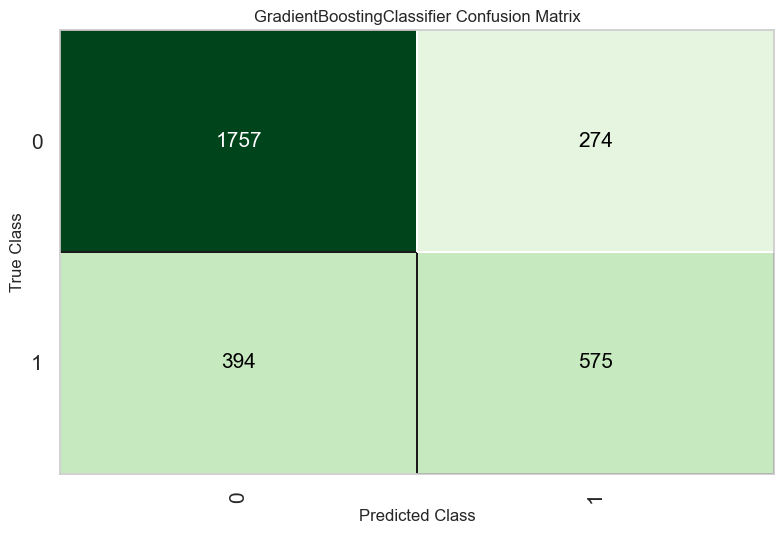

In [26]:
# Melakukan Evaluasi Model Gradient Boosting yang Telah Dituning
final_predictions = predict_model(tuned_gbc)

# Membuat Visualisasi Confusion Matrix untuk Model Gradient Boosting yang Telah Dituning
plot_model(tuned_gbc, plot='confusion_matrix')

## Random Forest Model

In [27]:
# Mengambil Model Random Forest dari PyCaret
rf_model = create_model('rf')

# Melakukan Hyperparameter Tuning Model Random Forest
tuned_rf = tune_model(
    rf_model,       
    optimize='AUC',        
    n_iter=30,             
    choose_better=True
)

,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.7600,0.8055,0.7600,0.7504,0.7465,0.4031,0.4157
1,0.7450,0.7858,0.7450,0.7331,0.7310,0.3667,0.3778
2,0.7667,0.7995,0.7667,0.7581,0.7536,0.4197,0.4328
3,0.7542,0.8018,0.7542,0.7438,0.7403,0.3893,0.4017
4,0.7675,0.8232,0.7675,0.7593,0.7541,0.4216,0.4355
5,0.7475,0.7965,0.7475,0.7362,0.7345,0.3764,0.3866
6,0.7767,0.8157,0.7767,0.7693,0.7656,0.4496,0.4611
7,0.7567,0.7982,0.7567,0.7473,0.7399,0.3870,0.4043
8,0.7600,0.8051,0.7600,0.7526,0.7407,0.3881,0.4107


,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.7550,0.8134,0.7550,0.7446,0.7428,0.3951,0.4052
1,0.7458,0.8012,0.7458,0.7349,0.7354,0.3793,0.3863
2,0.7708,0.8048,0.7708,0.7626,0.7601,0.4363,0.4463
3,0.7667,0.8158,0.7667,0.7581,0.7575,0.4324,0.4398
4,0.7767,0.8338,0.7767,0.7693,0.7656,0.4496,0.4611
5,0.7575,0.8007,0.7575,0.7476,0.7459,0.4037,0.4134
6,0.7900,0.8302,0.7900,0.7840,0.7810,0.4869,0.4965
7,0.7558,0.8044,0.7558,0.7457,0.7430,0.3961,0.4073
8,0.7650,0.8146,0.7650,0.7564,0.7513,0.4149,0.4289


Fitting 10 folds for each of 30 candidates, totalling 300 fits


In [28]:
# Melihat Parameter Terbaik dari Hasil Tuning Model Random Forest
best_params = tuned_rf.get_params()
for param, value in best_params.items():
    print(f"{param}: {value}")

bootstrap: True
ccp_alpha: 0.0
class_weight: {}
criterion: entropy
max_depth: 9
max_features: sqrt
max_leaf_nodes: None
max_samples: None
min_impurity_decrease: 0
min_samples_leaf: 6
min_samples_split: 10
min_weight_fraction_leaf: 0.0
monotonic_cst: None
n_estimators: 230
n_jobs: -1
oob_score: False
random_state: 42
verbose: 0
warm_start: False


,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
0,Random Forest Classifier,0.7670,0.8163,0.7670,0.7584,0.7575,0.4318,0.4396


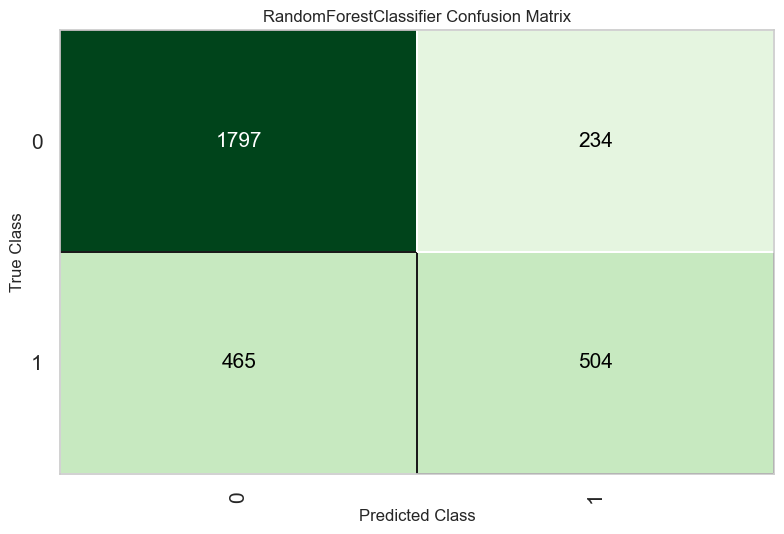

In [29]:
# Melakukan Evaluasi Model Random Forest yang Telah Dituning
final_predictions = predict_model(tuned_rf)

# Membuat Visualisasi Confusion Matrix untuk Model Random Forest yang Telah Dituning
plot_model(tuned_rf, plot='confusion_matrix')

# Employee Status Prediction and Feature Importance

## Global (Only Feature Importance)

In [30]:
# Mengambil Data Test Mentah dari PyCaret
X_test_raw = get_config('X_test')
y_test = get_config('y_test')

# Melakukan Preprocessing Data Test Mentah Menggunakan Pipeline PyCaret
pipeline = get_config('pipeline')
X_test_transformed = pipeline.transform(X_test_raw)

# Memastikan Data Test Hasil Preprocessing Berbentuk DataFrame
if not isinstance(X_test_transformed, pd.DataFrame):
    num_cols = get_config('X_train').columns 
    X_test_transformed = pd.DataFrame(X_test_transformed, columns=get_config('X_train').columns)

X_test_transformed.head().T

,9734,11150,3282,13982,5381
Age,0.924541,-0.256814,1.869626,-0.965628,0.215728
Gender,-1.188913,-1.188913,0.920323,0.920323,-1.188913
Marital_Status_Single,1.352109,-0.809781,-0.809781,-0.809781,-0.809781
Marital_Status_Divorced,-0.391633,-0.391633,-0.391633,-0.391633,-0.391633
Marital_Status_Married,-1.051881,1.042045,1.042045,1.042045,1.042045
...,...,...,...,...,...
Experience_Ratio,0.043091,-0.540351,0.043091,1.209976,-0.623700
Avg_Satisfaction,0.312262,-0.658771,1.283295,-0.658771,0.312262
Workload_Index,-0.201647,-1.002568,-0.201647,-0.246143,-0.335134
Projects_Per_Team_Member,-0.196075,-0.975903,-0.905010,-0.589928,0.512860


=== ANALISIS GLOBAL OCCLUSION SENSITIVITY (X_TEST + MANUAL FE) ===
Memproses 100 baris data uji dengan 37 kolom dasar...


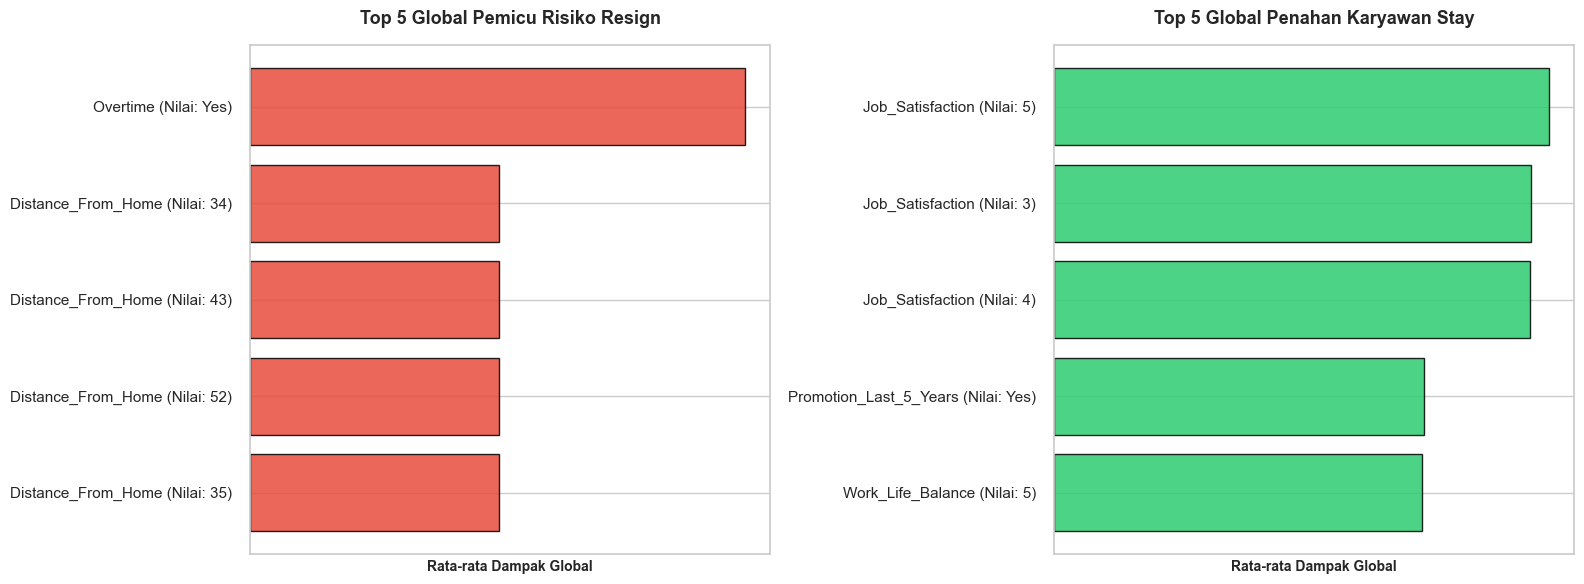


=== TOP 5 GLOBAL PEMICU RESIGN ===
                      Fitur_Value  Dampak_Rata2
0           Overtime (Nilai: Yes)      0.057341
1  Distance_From_Home (Nilai: 34)      0.028818
2  Distance_From_Home (Nilai: 43)      0.028816
3  Distance_From_Home (Nilai: 52)      0.028816
4  Distance_From_Home (Nilai: 35)      0.028807

=== TOP 5 GLOBAL PENAHAN STAY ===
                           Fitur_Value  Dampak_Rata2
0          Job_Satisfaction (Nilai: 5)      0.066181
1          Job_Satisfaction (Nilai: 3)      0.063750
2          Job_Satisfaction (Nilai: 4)      0.063644
3  Promotion_Last_5_Years (Nilai: Yes)      0.049426
4         Work_Life_Balance (Nilai: 5)      0.049146


In [31]:
# Set style visualisasi
sns.set_theme(style="whitegrid")

print("=" * 65)
print("=== ANALISIS GLOBAL OCCLUSION SENSITIVITY (X_TEST + MANUAL FE) ===")
print("=" * 65)

# Mengambil X_test Mentah dari Konfigurasi PyCaret
X_test_raw = get_config("X_test").head(100)
pipeline = get_config("pipeline")
model = tuned_ada 


# Function Feature Engineering
def create_features(df):
  df = df.copy()

  # Financial Ratios
  df["Income_Per_Year_At_Company"] = (
      df["Monthly_Income"] * 12 / (df["Years_At_Company"] + 1)
  )
  df["Income_Per_Project"] = df["Monthly_Income"] / df["Number_Of_Projects"]
  df["Income_Per_Age"] = df["Monthly_Income"] / df["Age"]

  # Career Ratios
  df["Experience_Ratio"] = df["Years_In_Current_Role"] / (
      df["Years_At_Company"] + 1
  )

  # Aggregasi Satisfaction
  sat_cols = [
      "Job_Satisfaction",
      "Work_Life_Balance",
      "Environment_Satisfaction",
      "Relationship_Satisfaction",
  ]
  df["Avg_Satisfaction"] = df[sat_cols].mean(axis=1)

  # Workload & Performance
  df["Workload_Index"] = df["Number_Of_Projects"] * df["Team_Size"]
  df["Projects_Per_Team_Member"] = df["Number_Of_Projects"] / df["Team_Size"]

  # Commute
  df["Commute_Speed_Index"] = df["Distance_From_Home"] / (
      df["Commute_Time_Minutes"]
  )

  return df


# Proses Global Occlusion Sensitivity
resign_impacts = {}
stay_impacts = {}

print(
    f"Memproses {len(X_test_raw)} baris data uji dengan"
    f" {len(X_test_raw.columns)} kolom dasar..."
)

for idx in range(len(X_test_raw)):
  row_raw = X_test_raw.iloc[[idx]].copy()

  # Prediksi Baseline
  row_eng_base = create_features(row_raw)
  row_trans_base = pipeline.transform(row_eng_base)
  base_prob = model.predict_proba(row_trans_base)[0][1] 
  base_pred = model.predict(row_trans_base)[0]

  # Normalisasi Label Prediksi Dasar
  is_resign = base_pred in [1, "Yes", "RESIGN"]

  # Uji Perturbasi Pada Setiap Kolom Data Mentah
  for col in X_test_raw.columns:
    temp_raw = row_raw.copy()
    original_val = temp_raw[col].values[0]

    # Perturbasi Nilai
    if pd.api.types.is_numeric_dtype(temp_raw[col]):
      temp_raw[col] = 0
    else:
      temp_raw[col] = "Unknown"

    try:
      temp_eng = create_features(temp_raw)
      temp_trans = pipeline.transform(temp_eng)
      new_prob = model.predict_proba(temp_trans)[0][1]

      # Hitung Dampak Perubahan Probabilitas
      impact = base_prob - new_prob

      # Label Feature Menggabungkan Nama Kolom Asli dan Nilai Spesifiknya
      feature_label = f"{col} (Nilai: {original_val})"

      # Kumpulkan Berdasarkan Tren Global Individu
      if is_resign:
        if impact > 0:  # Mendorong Naik ke Resign
          resign_impacts.setdefault(feature_label, []).append(impact)
      else:
        if impact < 0:  # Menahan Agar Tetap Stay
          stay_impacts.setdefault(feature_label, []).append(abs(impact))
    except:
      continue

# Merata-ratakan Dampak Global
def make_global_summary(impact_dict):
  if not impact_dict:
    return pd.DataFrame(columns=["Fitur_Value", "Dampak_Rata2"])
  avg_data = [(k, np.mean(v)) for k, v in impact_dict.items() if len(v) > 0]
  df = pd.DataFrame(avg_data, columns=["Fitur_Value", "Dampak_Rata2"])
  return df.sort_values(by="Dampak_Rata2", ascending=False).reset_index(
      drop=True
  )


df_global_resign = make_global_summary(resign_impacts).head(5)
df_global_stay = make_global_summary(stay_impacts).head(5)

# Visualisasi Hasil Top 5 Global (Resign & Stay)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Membuat Visualisasi Top 5 Pemicu Resign
if not df_global_resign.empty:
  df_res_plot = df_global_resign.iloc[::-1]  
  axes[0].barh(
      df_res_plot["Fitur_Value"],
      df_res_plot["Dampak_Rata2"],
      color="#e74c3c",
      alpha=0.85,
      edgecolor="black",
  )
  axes[0].set_title(
      "Top 5 Global Pemicu Risiko Resign", fontsize=13, fontweight="bold", pad=15
  )
  axes[0].set_xlabel("Rata-rata Dampak Global", fontsize=10, fontweight="bold")
  axes[0].set_xticks([])
  axes[0].grid(axis="x", linestyle="--", alpha=0.5)
else:
  axes[0].text(
      0.5,
      0.5,
      "Tidak ada data pemicu resign",
      ha="center",
      va="center",
      transform=axes[0].transAxes,
  )

# Membuat Visualisasi Top 5 Penahan Stay
if not df_global_stay.empty:
  df_sty_plot = df_global_stay.iloc[::-1] 
  axes[1].barh(
      df_sty_plot["Fitur_Value"],
      df_sty_plot["Dampak_Rata2"],
      color="#2ecc71",
      alpha=0.85,
      edgecolor="black",
  )
  axes[1].set_title(
      "Top 5 Global Penahan Karyawan Stay",
      fontsize=13,
      fontweight="bold",
      pad=15,
  )
  axes[1].set_xlabel("Rata-rata Dampak Global", fontsize=10, fontweight="bold")
  axes[1].set_xticks([])
  axes[1].grid(axis="x", linestyle="--", alpha=0.5)
else:
  axes[1].text(
      0.5,
      0.5,
      "Tidak ada data penahan stay",
      ha="center",
      va="center",
      transform=axes[1].transAxes,
  )

plt.tight_layout()
plt.show()

# Cetak Ringkasan Teks di Console
print("\n=== TOP 5 GLOBAL PEMICU RESIGN ===")
print(df_global_resign)

print("\n=== TOP 5 GLOBAL PENAHAN STAY ===")
print(df_global_stay)

## Local

=== ANALISIS LOCAL FEATURE IMPORTANCE (SINGLE EMPLOYEE) ===

Hasil Prediksi Karyawan : RESIGN
Tingkat Keyakinan       : 57.28%
Probabilitas Resign     : 0.5728



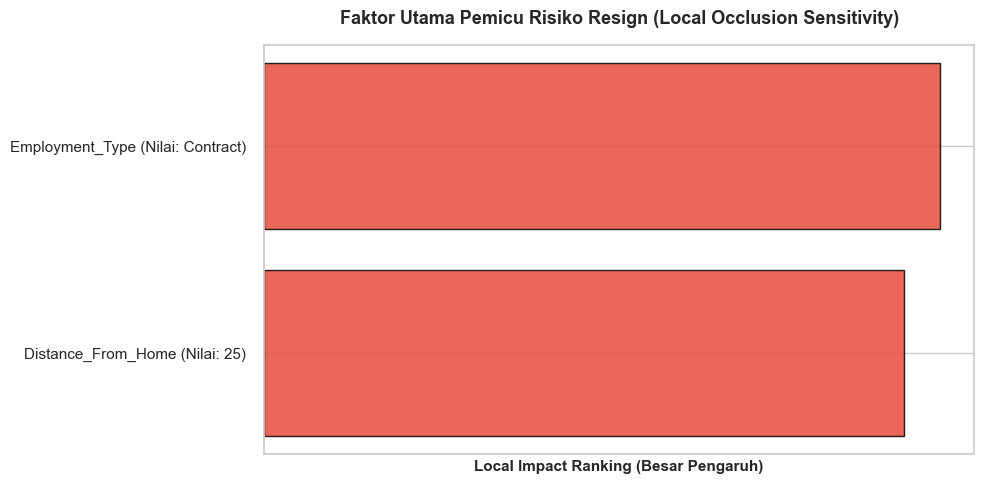

In [33]:
# Set style visualisasi
sns.set_theme(style="whitegrid")

print("=" * 65)
print("=== ANALISIS LOCAL FEATURE IMPORTANCE (SINGLE EMPLOYEE) ===")
print("=" * 65)

# Ambil pipeline dan model dari PyCaret
pipeline = get_config("pipeline")
model = tuned_ada

# Membuat 1 Data Sampel Karyawan (Input Tunggal)
sample_data = pd.DataFrame([{
    "Age": 23,
    "Gender": "Male",
    "Marital_Status": "Single",
    "Education_Level": "Bachelor",
    "Department": "IT",
    "Job_Role": "Data Analyst",
    "Employment_Type": "Contract",
    "Years_At_Company": 5,
    "Years_In_Current_Role": 5,
    "Monthly_Income": 5000,
    "Salary_Hike_Percent": 10.0,
    "Job_Level": 2,
    "Performance_Rating": 4,
    "Job_Satisfaction": 3,
    "Work_Life_Balance": 2,
    "Environment_Satisfaction": 2,
    "Relationship_Satisfaction": 1,
    "Training_Hours_Last_Year": 20,
    "Overtime": "No",
    "Remote_Work": "No",
    "Business_Travel": "Never",
    "Distance_From_Home": 25,
    "Commute_Time_Minutes": 50,
    "Number_Of_Projects": 10,
    "Team_Size": 5,
    "Manager_Rating": 2,
    "Absence_Days": 5,
    "Promotion_Last_5_Years": "No",
    "Stock_Option": "No",
}])

# Function Feature Engineering
def create_features(df):
    df = df.copy()
    # Financial Ratios
    df["Income_Per_Year_At_Company"] = (
        df["Monthly_Income"] * 12 / (df["Years_At_Company"] + 1)
    )
    df["Income_Per_Project"] = df["Monthly_Income"] / df["Number_Of_Projects"]

    df["Income_Per_Age"] = df["Monthly_Income"] / df["Age"]

    # Career Ratios
    df["Experience_Ratio"] = df["Years_In_Current_Role"] / (
        df["Years_At_Company"] + 1
    )

    # Aggregasi Satisfaction
    sat_cols = [
        "Job_Satisfaction",
        "Work_Life_Balance",
        "Environment_Satisfaction",
        "Relationship_Satisfaction",
    ]
    df["Avg_Satisfaction"] = df[sat_cols].mean(axis=1)

    # Workload & Performance
    df["Workload_Index"] = df["Number_Of_Projects"] * df["Team_Size"]
    df["Projects_Per_Team_Member"] = df["Number_Of_Projects"] / df["Team_Size"]

    # Commute
    df["Commute_Speed_Index"] = df["Distance_From_Home"] / (
        df["Commute_Time_Minutes"]
    )
    return df

# Prediksi Baseline untuk Sampel Tunggal
sample_eng = create_features(sample_data)
sample_trans = pipeline.transform(sample_eng)

base_prob = model.predict_proba(sample_trans)[0][1]  
base_pred = model.predict(sample_trans)[0]

# Normalisasi Label Prediksi
is_resign = base_pred in [1, "Yes", "RESIGN"]
status_label = "RESIGN" if is_resign else "STAYED"
confidence = max(model.predict_proba(sample_trans)[0]) * 100

print(f"\nHasil Prediksi Karyawan : {status_label}")
print(f"Tingkat Keyakinan       : {confidence:.2f}%")
print(f"Probabilitas Resign     : {base_prob:.4f}\n")

# Proses Local Occlusion Sensitivity
importance_results = []

for col in sample_data.columns:
    temp_raw = sample_data.copy()
    original_val = temp_raw.loc[0, col]

    # Lakukan Perturbasi (occlusion) Pada Data Mentah
    if pd.api.types.is_numeric_dtype(temp_raw[col]):
        temp_raw.loc[0, col] = 0
    else:
        temp_raw.loc[0, col] = "Unknown"

    try:
        temp_eng = create_features(temp_raw)
        temp_trans = pipeline.transform(temp_eng)
        new_prob = model.predict_proba(temp_trans)[0][1]

        # Menghitung Dampak Perubahan Terhadap Probabilitas Resign
        impact = base_prob - new_prob 
        importance_results.append(
            {"Fitur": col, "Nilai_Asli": original_val, "Dampak": impact}
        )
    except:
        continue

df_local = pd.DataFrame(importance_results)

# Visualisasi Dinamis Berdasarkan Status Prediksi (Resign vs Stayed)
plt.figure(figsize=(10, 5))

if status_label == "RESIGN":
    # Ambil fitur yang mendorong naik ke Resign (Dampak > 0), urutkan terbesar, batasi top 5
    df_filtered = (
        df_local[df_local["Dampak"] > 0]
        .sort_values(by="Dampak", ascending=False)
        .head(5)
    )
    title = "Faktor Utama Pemicu Risiko Resign (Local Occlusion Sensitivity)"
    bar_color = "#e74c3c"  # Merah
else:
    # Ambil fitur yang menahan agar tetap Stay (Dampak < 0), ambil nilai absolut terbesar, batasi top 5
    df_filtered = df_local[df_local["Dampak"] < 0].copy()
    df_filtered["Abs_Dampak"] = df_filtered["Dampak"].abs()
    df_filtered = df_filtered.sort_values(by="Abs_Dampak", ascending=False).head(5)
    df_filtered = df_filtered.iloc[::-1]
    title = "Faktor Utama Penahan Retensi / Karyawan Tetap Setia"
    bar_color = "#2ecc71"  # Hijau

if df_filtered.empty:
    print("Tidak ada fitur spesifik yang memenuhi kriteria dampak.")
else:
    if status_label == "STAYED":
        x_values = df_filtered["Abs_Dampak"]
        y_labels = [
            f"{row['Fitur']} (Nilai: {row['Nilai_Asli']})"
            for _, row in df_filtered.iterrows()
        ]
    else:
        df_filtered = df_filtered.iloc[::-1]
        y_labels = [
            f"{row['Fitur']} (Nilai: {row['Nilai_Asli']})"
            for _, row in df_filtered.iterrows()
        ]
        x_values = df_filtered["Dampak"]

    plt.barh(y_labels, x_values, color=bar_color, alpha=0.85, edgecolor="black")
    plt.title(title, fontsize=13, fontweight="bold", pad=15)
    plt.xlabel("Local Impact Ranking (Besar Pengaruh)", fontsize=11, fontweight="bold")
    plt.xticks([])
    plt.grid(axis="x", linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.show()

print("=" * 65)